# Tether feature selection

Analyses tether features w/wo scaling in order to halp the user select those suitable for ML and NN classification. Specifically, shows univariate ANOVA and Mutual information scores, as well as pairwise distributions.

Does not write any output. The selected features should be specified in the ML and NN classification notebooks.

## Initialization

In [2]:
import os
import sys
import subprocess
import importlib
import pickle
import logging
import functools

import numpy as np
import scipy as sp
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import IPython
from IPython.core.display import HTML

import sklearn as sk
import sklearn.feature_selection
import sklearn.compose
from sklearn import preprocessing as sk_preproc
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression
import sklearn.discriminant_analysis
from sklearn.metrics import confusion_matrix
from sklearn.inspection import DecisionBoundaryDisplay
#import graphviz

import pyto
from pyto.io.pandas_io import PandasIO  
from pyto.projects.presynaptic import Presynaptic
from pyto.ai.ml_supervised import MLSupervised
import pyto.ai.feature_transform_tethers  
from pyto.ai.feature_transform_tethers import combine_features, get_transformer_standard
from pyto.ai.feature_transform_tethers import transform_df, get_transformer_robust
from pyto.ai.feature_transform_tethers import get_transformer_logstd, get_transformer_logrobust
from pyto.ai.feature_transform_tethers import check_data

#import annotation_functions as annot_func
#from ml import combine_features, evaluate, evaluate_logreg, evaluate_decisiontree
#from ml import evaluate_randomforest, initialize_data
#from ml import plot_param_search_cv, fit_print_single, fit_print_cv
#import feature_transform
#from feature_transform import transform_df, get_transformer_1, get_columns
#from feature_transform import get_transformer_logstd, get_transformer_logrobust

%autosave 0
sys.version

Autosave disabled


'3.11.10 | packaged by conda-forge | (main, Sep 10 2024, 11:01:28) [GCC 13.3.0]'

In [3]:
# Settings

# force showing all rows in a table (default 60 rows)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)

# seaborn plots
#sns.set_theme()
#sns.set_context('talk')
#sns.reset_orig()

# set hostname
hostname = os.uname()[1]
print(f"Host: {hostname}")

Host: rauna


In [4]:
# remove seaborn warnings
import warnings
warnings.filterwarnings("ignore", "use_inf_as_na option")
warnings.filterwarnings("ignore", "The default of observed=False")

### Figures

In [5]:
# Useful functions for figures

# set plot parameters
def set_plot(plot_type):
    
    # for making figures 
    if plot_type == 'figure_save':
        # for some reason need to repeat
        %matplotlib qt
        plt.rcParams['font.size'] = 15
        %matplotlib qt
        plt.rcParams['font.size'] = 15
    
    # figure-like inline
    if plot_type == 'figure_inline':
        %matplotlib inline
        plt.rcParams['font.size'] = 16
    
    # standard inline
    if plot_type == 'inline':
        %matplotlib inline
        plt.rcParams["figure.figsize"] = [4.5, 3]  # workaround changed size 2.2023

In [6]:
# choose figure type, uncomment one
#plot_type = 'figure_save' 
plot_type = 'figure_inline'
plot_type = 'inline'

set_plot(plot_type)

### Development help

Need to execute only for development

In [344]:
qtconsole

In [4]:
# enable reloading
%load_ext autoreload
%autoreload 2

In [ ]:
# disable reloading
%autoreload 0

## General parameters and setup

In [7]:
# Parameters 

# Need to be consistent with output of munc13-snap25

# Directory where input data for ML is saved (absolute or 
# relative to this dir). These incude:
#   - munc13 snap25 presynaptic project data
#   - additional munc13 snap25 presynaptic analysis
#   - manual annotations
input_dir = 'input_data/tethers'

# The following are file names without extension

# Tether indexed and scalar data (original data, additional 
# features and annotations)
data_base = 'm13-snap25_data'
metadata_base = 'm13-snap25_metadata'


# Initialization

# make paths from the above (absolute or relative to this directory)
data_path = os.path.join(input_dir, data_base)
metadata_path = os.path.join(input_dir, metadata_base)

# Initialize object used to handle additional munc13-snap25 features
df_io = PandasIO(calling_dir=os.getcwd())
feat = Presynaptic(df_io=df_io)

## Get features

#### Read features from Munc13-SNAP25 project

In [8]:
# useful groups of columns

# columns that have to be present in the feature table
common_cols = ['group', 'identifiers', 'ids']

# annotation columns (labels)
#snare_annot_cols = ['snare_no', 'snare', 'snare_big', 'snare_code']
#snare_annot_cols_all = [
#    'snare_no', 'snare', 'snare_big', 'snare_code',
#    'Fit_snare', 'Comment_snare', 'Presentation_snare', 'Grayscale_snare']
munc13_annot_cols = ['mun_no', 'mun', 'munc13', 'munc13_code']
#munc13_annot_cols_all = [
#    'Fit_munc13', 'mun_no', 'mun', 'munc13', 'munc13_code',
#    'Comment_munc13', 'Presentation_munc13', 'Grayscale_munc13', 'Actual tether']
#annot_cols = snare_annot_cols + munc13_annot_cols
annot_cols = munc13_annot_cols

# feature columns
feature_cols = [
    'thresh', 'thresh_rank', 'density_mean', 'density_std',
    'length_nm', 'length_min_nm', 'length_median_nm', 'length_max_nm',
    'boundary_distance_nm', 'distance_nm', 
    'surface', 'volume', 'surface_nm', 'volume_nm', 'euler']

features_len = [
    'length_nm', 'length_min_nm', 'length_median_nm', 'length_max_nm',
    'boundary_distance_nm', 'distance_nm', 'length_curve', 'length_max_min', 
    'length_curve_ratio', 'length_max_min_ratio', 'length_max_min_relative',
    'length_bound_ratio']
features_mor = [ 
    'thresh_rank', 'volume_nm', 'surface_nm', 'v-s', 'svr',
    'len_v_ratio', 'n_loops', 'loops_v_ratio'] #, 'euler', 'n_holes']

# basic features 
features_basic = [
    'thresh', 'thresh_rank', 'density_mean', 'density_std',
    'boundary_distance_nm', 'distance_nm', 
    'length_nm', 'length_min_nm', 'length_median_nm', 'length_max_nm',
    'surface_nm', 'volume_nm', 'euler', 'n_loops']

# standard features (original and derived wo highly correlated)
features_std = [
    'length_nm', 'length_max_nm',
    'boundary_distance_nm', 'distance_nm', 'length_curve', 'length_max_min', 
    'length_curve_ratio', 'length_max_min_ratio', 
    'length_bound_ratio',
    'thresh_rank', 'volume_nm', 'v-s', 'svr',
    'len_v_ratio', 'n_loops', 'loops_v_ratio'] 


In [9]:
# Read data 

input_data = df_io.read_table(
    base=data_path, 
    out_desc='Full analysis with Munc13 annotations')
metadata = df_io.read_table(
    base=metadata_path, 
    out_desc='Full analysis with Munc13 annotations metadata')

# extract annotated
#snare_data = annot_func.get_snare(input_data).copy()
munc13_data = MLSupervised.get_labeled(df=input_data, column='munc13').copy()

# add combinations of features
data, _ = combine_features(input_data)
munc13_data, comb_features = combine_features(munc13_data)
#snare_data, comb_features = combine_features(snare_data)

# distinguish annotated and not annotated
#data['munc13_code'] = data['munc13_code'].cat.add_categories([-1])
#data['munc13_code'] = data['munc13_code'].fillna(-1)
data['munc13_annot'] = data['munc13_code'].notna()
#data['snare_code'] = data['snare_code'].cat.add_categories([-1])
#data['snare_code'] = data['snare_code'].fillna(-1)
#data['snare_annot'] = data['snare_code'].notna()

# check data
check_data(input_data, cols=common_cols+feature_cols)
check_data(
    munc13_data, cols=common_cols+munc13_annot_cols+comb_features)
#annot_func.check_data(snare_data, cols=common_cols+snare_annot_cols+comb_features)

Read Full analysis with Munc13 annotations pickled json string from input_data/tethers/m13-snap25_data_json.pkl
Read Full analysis with Munc13 annotations metadata pickled json string from input_data/tethers/m13-snap25_metadata_json.pkl
Looks fine
Looks fine


#### Show feature table format

Features table should be generated externally. Here, the required table format is shown.

In [10]:
# columns: required (the first three) and features (the rest)
munc13_data.columns

Index(['group', 'identifiers', 'ids', 'boundaries', 'boundary_distance',
       'boundary_distance_nm', 'density_max', 'density_mean', 'density_min',
       'density_std', 'distance', 'distance_nm', 'euler', 'length',
       'length_nm', 'n_loops', 'surface', 'surface_nm', 'thresh', 'volume',
       'volume_nm', 'thresh_rank', 'thresh_rank_by_teth', 'length_min',
       'length_min_nm', 'length_median', 'length_median_nm', 'length_max',
       'length_max_nm', 'Fit_munc13', 'mun_no', 'mun', 'munc13', 'munc13_code',
       'Comment_munc13', 'Presentation_munc13', 'Grayscale_munc13', 'snare_no',
       'snare', 'snare_big', 'snare_code', 'Fit_snare', 'Comment_snare',
       'Presentation_snare', 'Grayscale_snare', 'length_curve',
       'length_curve_ratio', 'length_max_min', 'length_max_min_ratio',
       'length_max_min_relative', 'length_bound_ratio', 'v-s', 'svr',
       'len_v_ratio', 'euler_v_ratio', 'loops_v_ratio', 'n_holes'],
      dtype='object')

In [11]:
# Fearure values for the first five tethers
munc13_data.head()

,group,identifiers,ids,boundaries,boundary_distance,boundary_distance_nm,density_max,density_mean,density_min,density_std,...,length_max_min,length_max_min_ratio,length_max_min_relative,length_bound_ratio,v-s,svr,len_v_ratio,euler_v_ratio,loops_v_ratio,n_holes
2,m13_ctrl,m13_ctrl_108,100,"[2, 77]",3.000000,5.268000,2119.336182,1672.644097,598.994324,395.322956,...,1.700267,1.186342,0.186342,0.577350,0,1.0,0.057118,0.028571,0.000000,0
7,m13_ctrl,m13_ctrl_108,219,"[2, 174]",3.741657,6.570350,2242.574463,1807.221024,1199.061890,339.597011,...,1.085060,1.100239,0.100239,0.606977,0,1.0,0.091647,0.041667,0.000000,0
15,m13_ctrl,m13_ctrl_108,513,"[2, 74]",4.898979,8.602608,2377.110352,1938.605679,1064.813354,328.653875,...,4.966718,1.400000,0.400000,0.692820,0,1.0,0.047212,0.000000,0.014706,0
17,m13_ctrl,m13_ctrl_108,536,"[2, 174]",3.741657,6.570350,2397.244385,1693.778358,622.810547,496.907970,...,0.000000,1.000000,0.000000,0.591608,0,1.0,0.085461,0.041667,0.000000,0
21,m13_ctrl,m13_ctrl_108,667,"[2, 23]",4.358899,7.654227,2445.451416,2088.590729,654.443726,433.078957,...,0.760742,1.064581,0.064581,0.649786,0,1.0,0.115799,0.050000,0.000000,0


In [12]:
# Basic stats
munc13_data.describe()

,ids,boundary_distance,boundary_distance_nm,density_max,density_mean,density_min,density_std,distance,distance_nm,euler,...,length_max_min,length_max_min_ratio,length_max_min_relative,length_bound_ratio,v-s,svr,len_v_ratio,euler_v_ratio,loops_v_ratio,n_holes
count,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,...,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.0
mean,1075.256293,3.988041,7.003000,1507.020229,1103.215494,76.054084,328.567113,3.981209,6.991002,-0.453089,...,7.972826,1.713931,0.713931,0.614697,0.805492,0.995712,0.062677,0.013704,0.010145,0.0
std,1022.777424,1.713241,3.008452,1392.505601,1398.107145,1476.143409,108.013976,1.681957,2.953517,2.252566,...,7.417517,0.715957,0.715957,0.244032,1.787101,0.008729,0.039579,0.030851,0.013695,0.0
min,3.000000,1.000000,1.756000,-2130.668701,-2586.726894,-4081.192139,111.676207,1.435027,2.519907,-13.000000,...,0.000000,1.000000,0.000000,0.105118,0.000000,0.948571,0.008056,-0.062500,0.000000,0.0
25%,376.000000,3.000000,5.268000,677.318909,379.008451,-689.549988,242.529647,2.810294,4.934877,-1.000000,...,2.806825,1.243163,0.243163,0.415227,0.000000,0.995037,0.033184,-0.007519,0.000000,0.0
50%,695.000000,3.741657,6.570350,1689.760132,1289.889480,224.183914,343.451606,3.610716,6.340417,0.000000,...,5.615757,1.485221,0.485221,0.618347,0.000000,1.000000,0.053441,0.000000,0.004464,0.0
75%,1399.000000,4.582576,8.047003,2656.633057,2218.088135,1199.061890,407.846911,4.717287,8.283556,1.000000,...,11.063834,1.991507,0.991507,0.784465,1.000000,1.000000,0.082253,0.028571,0.017316,0.0
max,6135.000000,10.392305,18.248887,3751.339355,3526.406770,3013.794434,672.859313,11.751065,20.634870,1.000000,...,56.619026,5.825906,4.825906,1.290994,10.000000,1.000000,0.250622,0.125000,0.125000,0.0


## Univariate stats

### Not scaled

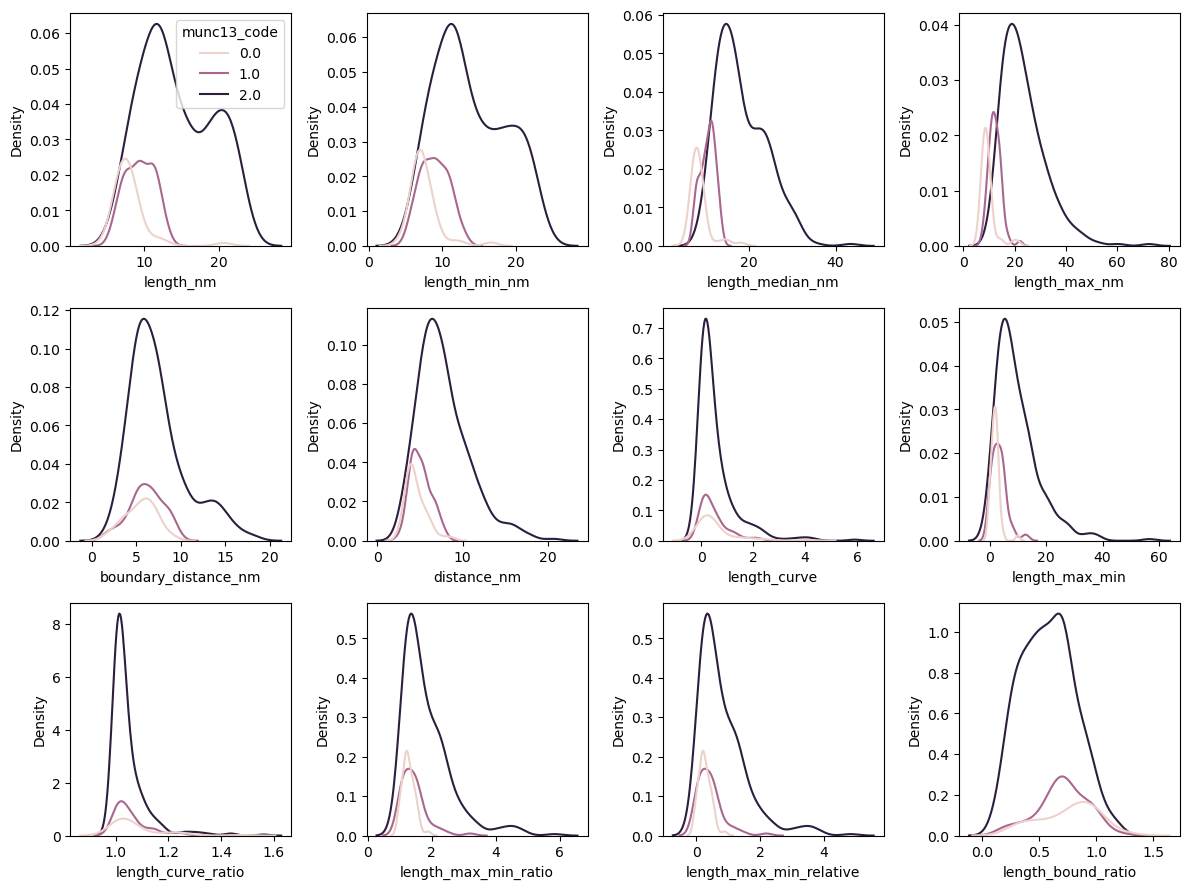

In [13]:
features = features_len
    
n_cols = 4
data_loc = munc13_data

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

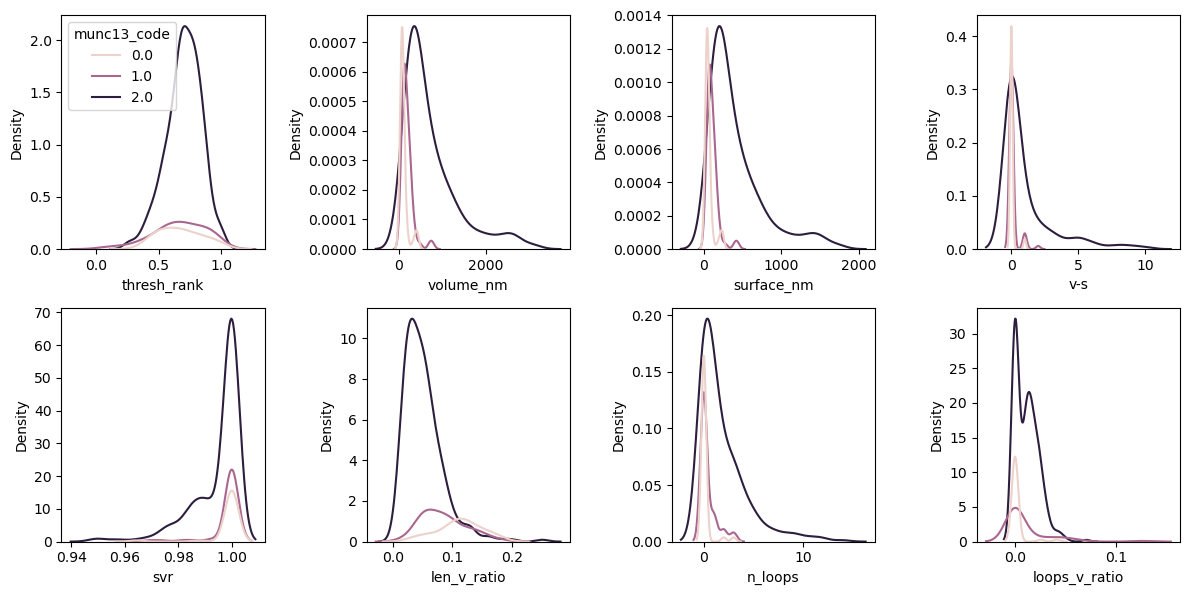

In [14]:
features = features_mor
    
n_cols = 4
data_loc = munc13_data

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

In [15]:
# ANOVA score

features = ['density_min', 'density_max'] + features_len + features_mor
target = 'munc13_code'
data_loc = munc13_data

sel = sk.feature_selection.SelectPercentile(
    score_func=sk.feature_selection.f_classif)
ml = MLSupervised(
    estim=sel, scoring='f1_macro', cv=None, 
    fit_single=True, print_coefs=True)
ml.evaluate(data=data_loc, features=features, target=target);

,Scores,P values
density_min,2.178957,1.148150e-01
density_max,0.817239,4.425579e-01
length_nm,50.176443,1.038704e-19
length_min_nm,49.809409,1.374998e-19
length_median_nm,83.572894,5.397628e-30
length_max_nm,75.420895,1.280455e-27
boundary_distance_nm,6.628950,1.508087e-03
distance_nm,33.339518,6.814505e-14
length_curve,0.382084,6.827445e-01
length_max_min,28.100233,5.574978e-12


In [16]:
# Mutual information score

features = ['density_min', 'density_max'] + features_len + features_mor
target = 'munc13_code'
data_loc = munc13_data

sel = sk.feature_selection.SelectPercentile(
    score_func=sk.feature_selection.mutual_info_classif)
ml = MLSupervised(
    estim=sel, scoring='f1_macro', cv=None, 
    fit_single=True, print_coefs=True)
ml.evaluate(data=data_loc, features=features, target=target);

,Scores,P values
density_min,0.016538,None
density_max,0.036251,None
length_nm,0.167304,None
length_min_nm,0.201958,None
length_median_nm,0.391568,None
length_max_nm,0.365690,None
boundary_distance_nm,0.049083,None
distance_nm,0.118247,None
length_curve,0.008353,None
length_max_min,0.179127,None


### Scaler standard

In [17]:
# Transform data

transformer_func = get_transformer_standard
munc13_data_standard = transform_df(
    data=munc13_data, transformer=transformer_func)

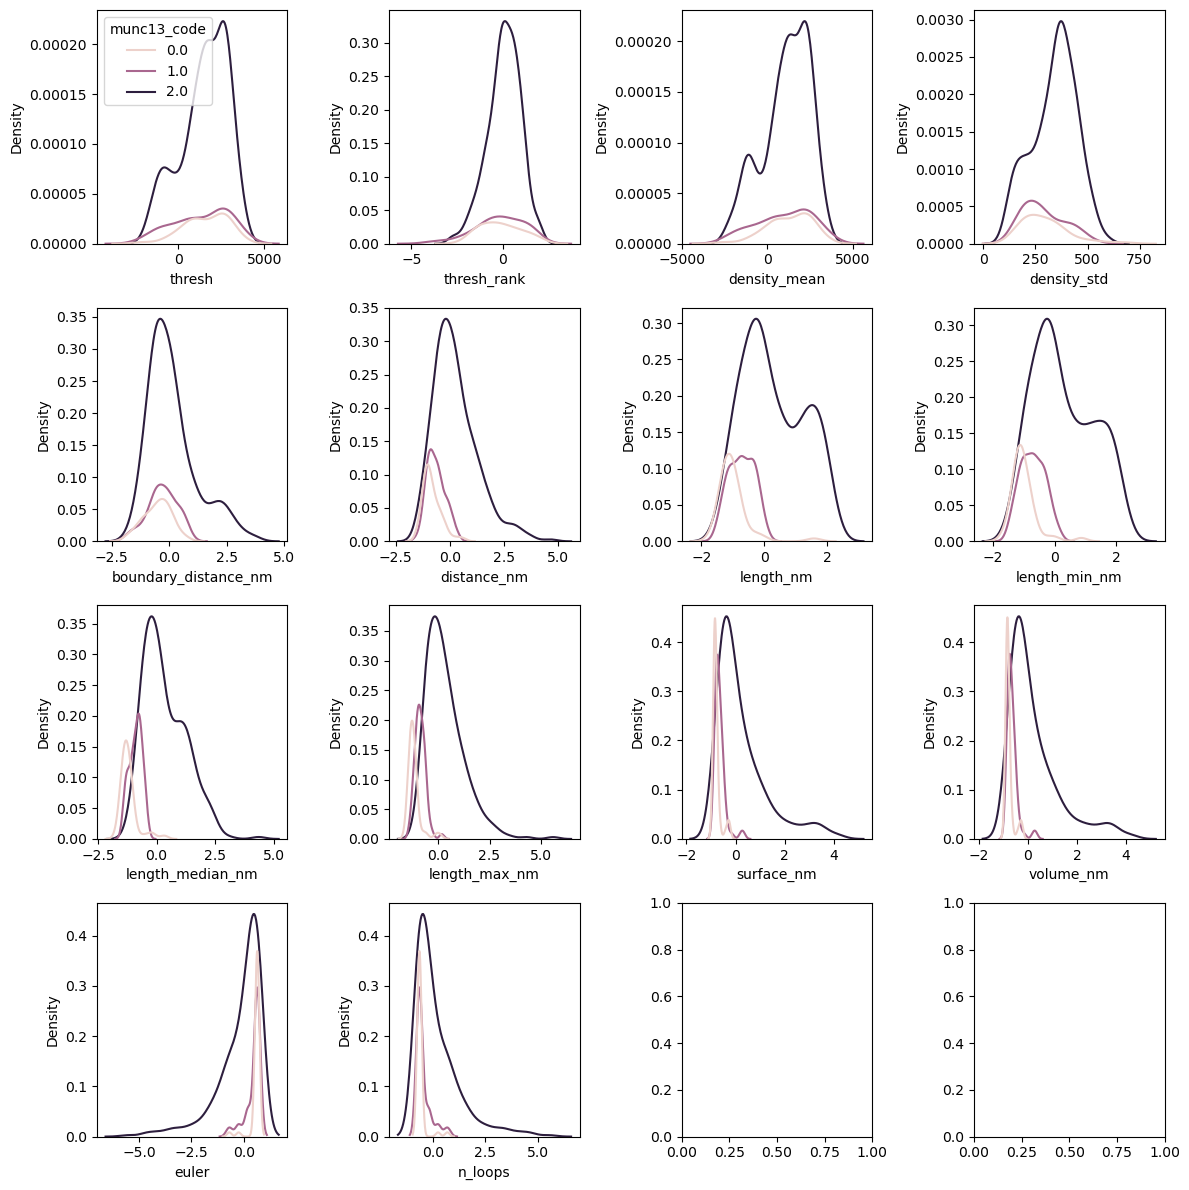

In [18]:
features = features_basic
    
n_cols = 4
data_loc = munc13_data_standard

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

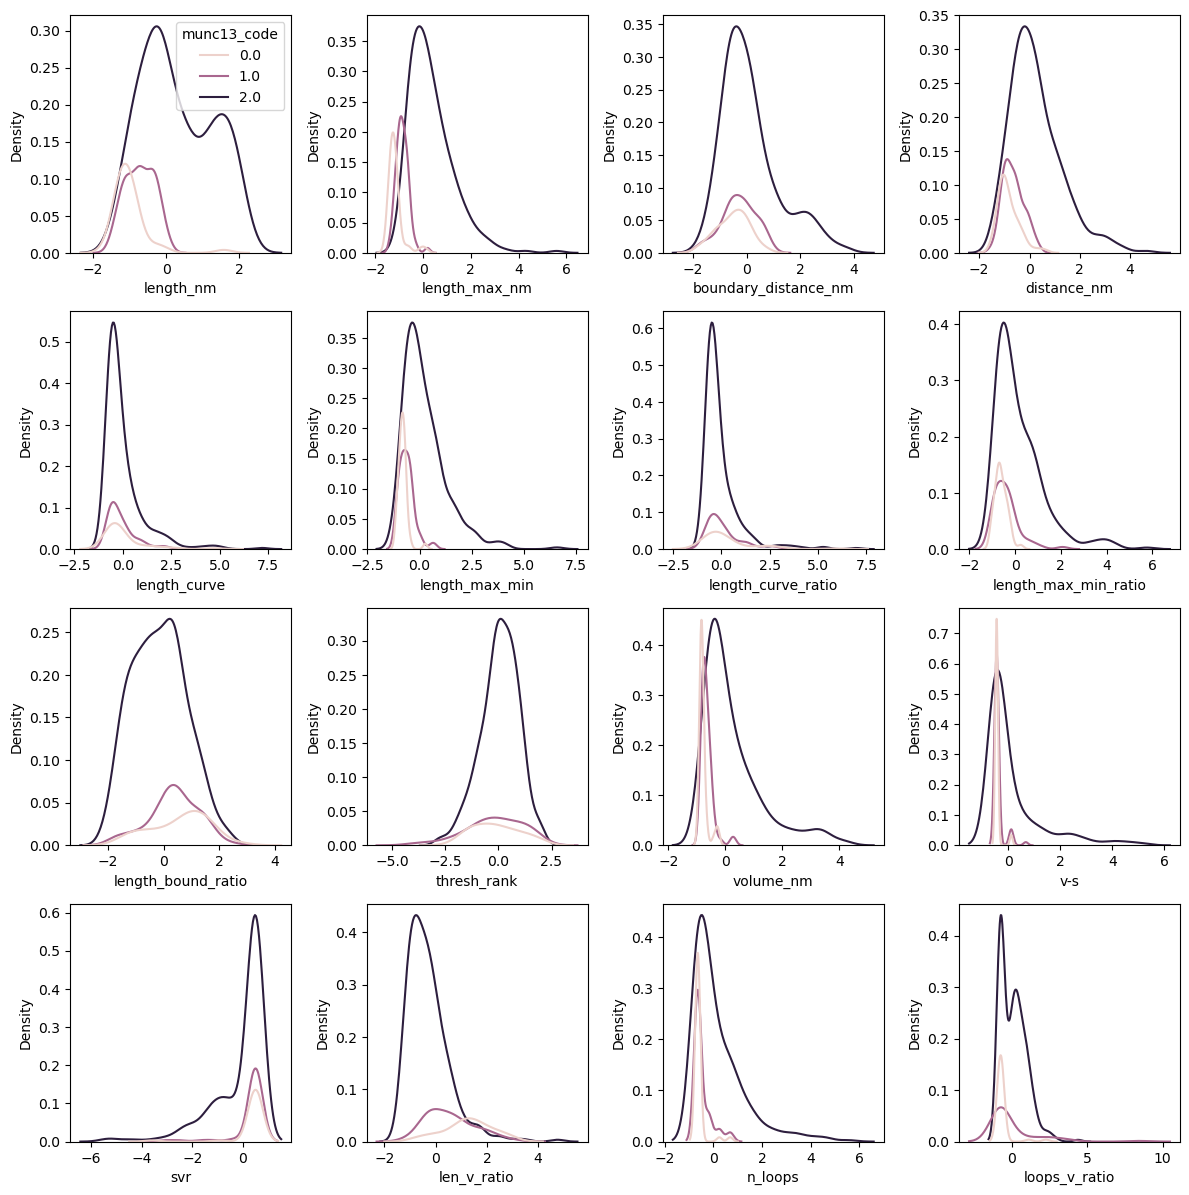

In [19]:
features = features_std
    
n_cols = 4
data_loc = munc13_data_standard

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

### Scaler robust

In [20]:
# Transform data

transformer_func = get_transformer_robust
munc13_data_robust = transform_df(
    data=munc13_data, transformer=transformer_func)

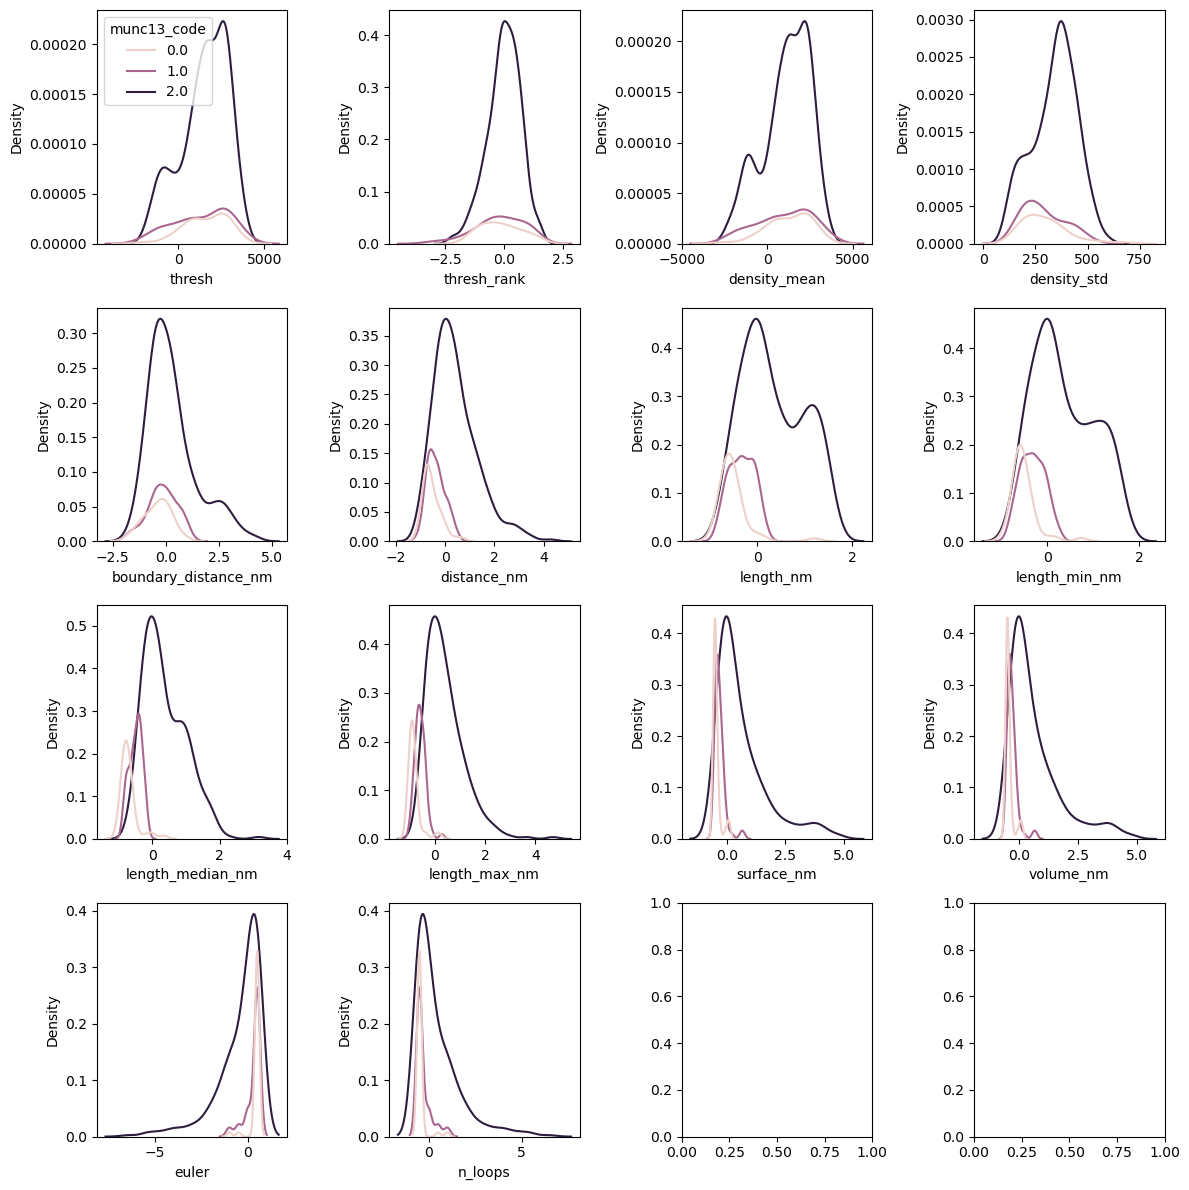

In [21]:
features = features_basic
    
n_cols = 4
data_loc = munc13_data_robust

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

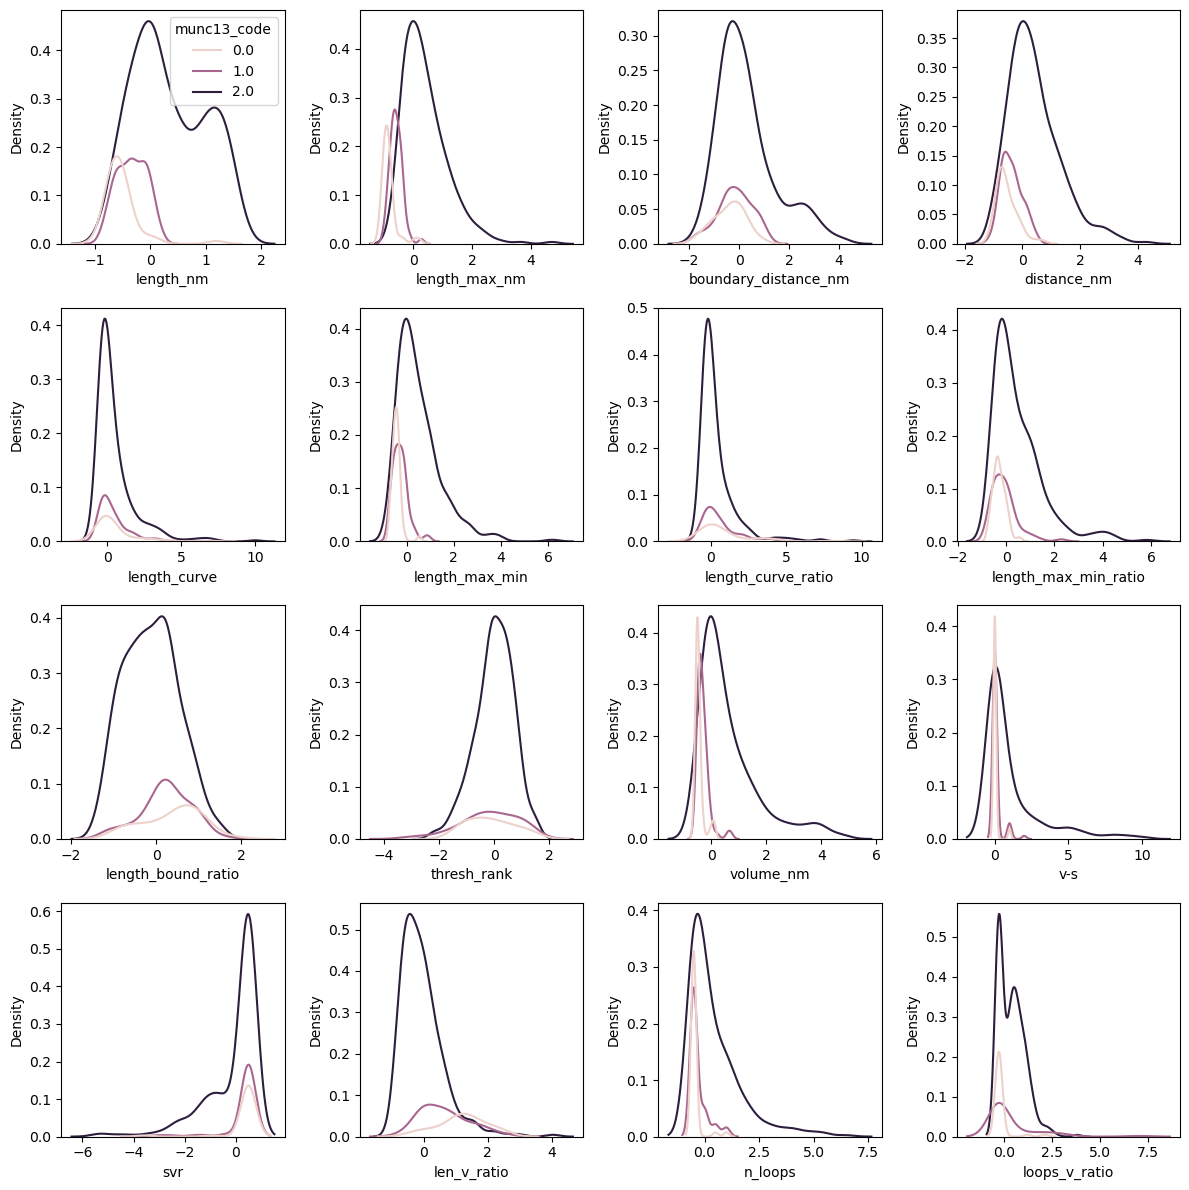

In [22]:
features = features_std
    
n_cols = 4
data_loc = munc13_data_robust

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

### Scaler logrobust

In [23]:
# Transform data

transformer_func = get_transformer_logrobust
munc13_data_logrobust = transform_df(
    data=munc13_data, transformer=transformer_func)

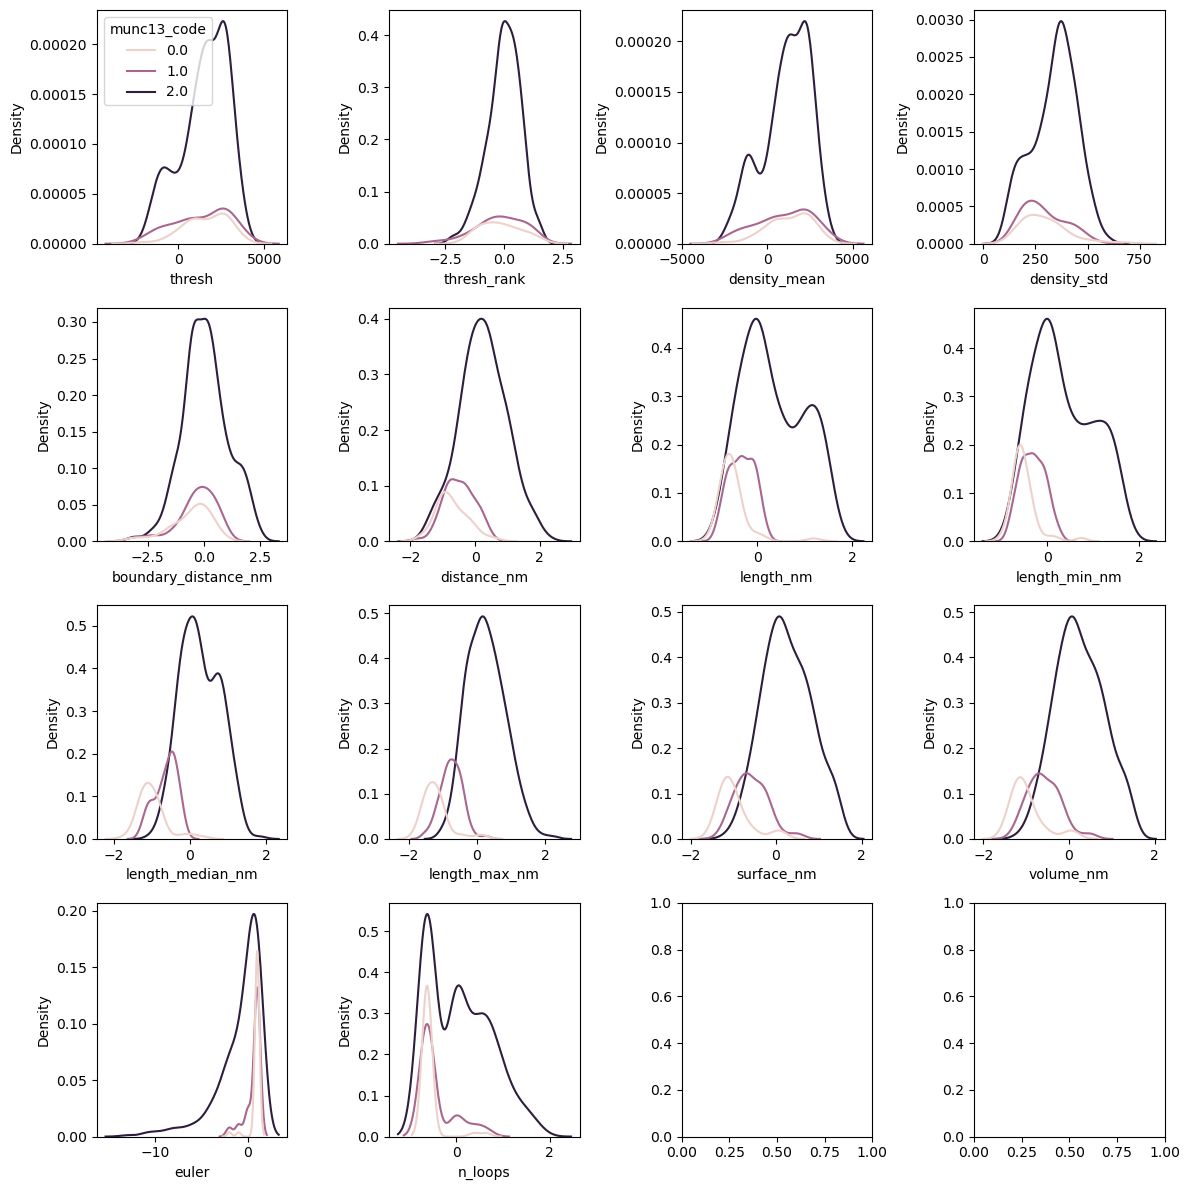

In [24]:
features = features_basic
    
n_cols = 4
data_loc = munc13_data_logrobust

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

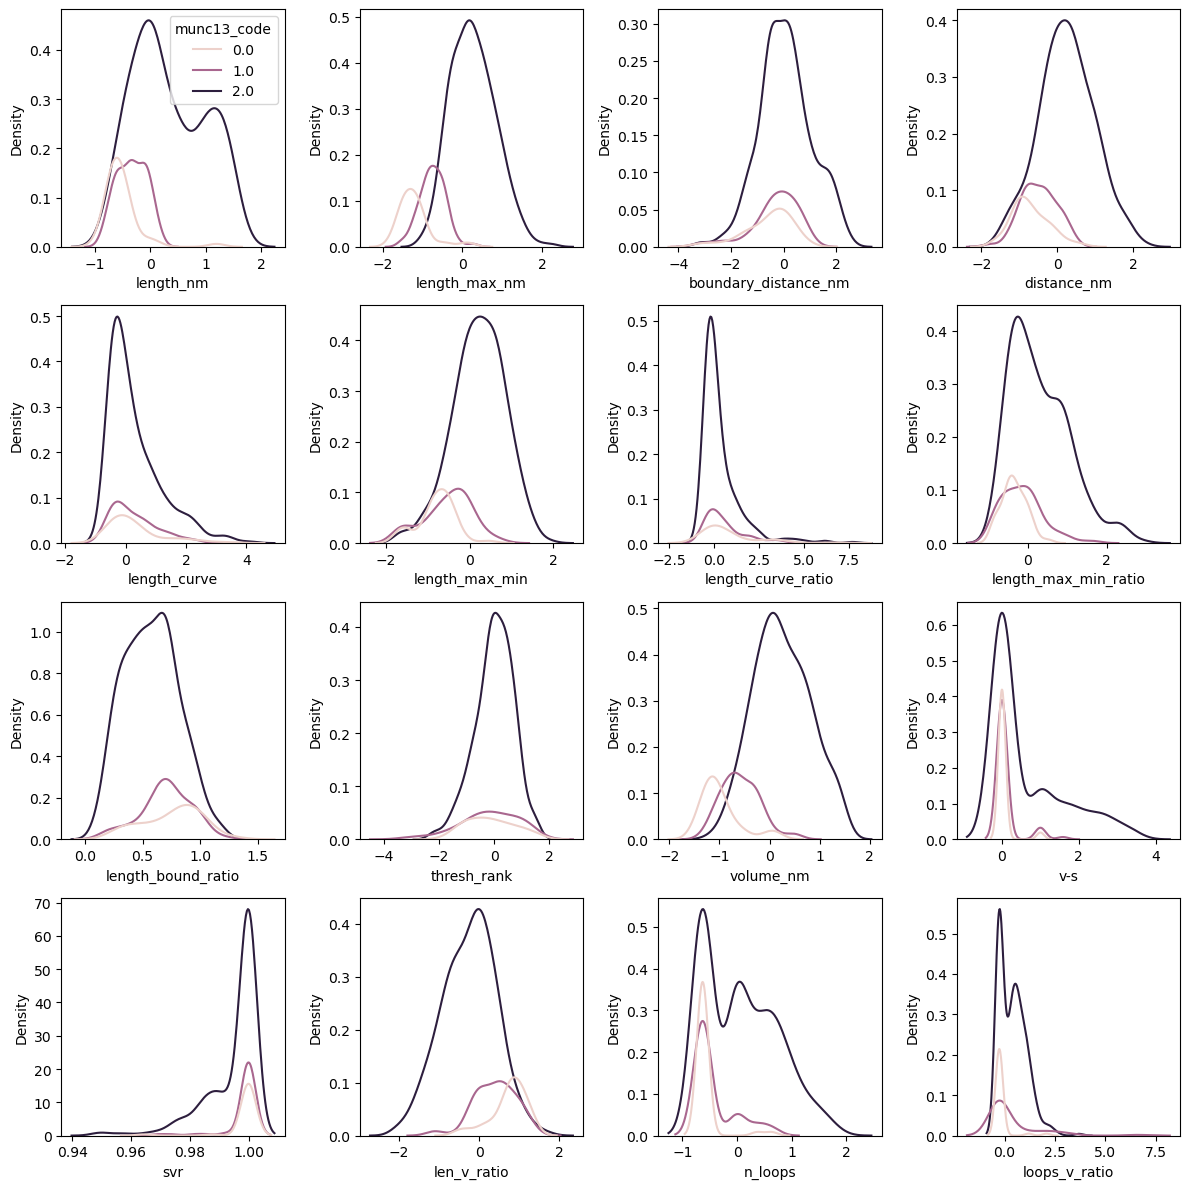

In [25]:
features = features_std
    
n_cols = 4
data_loc = munc13_data_logrobust

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

### Scaler logstandard

In [26]:
# Transform data

transformer_func = get_transformer_logstd
munc13_data_logstd = transform_df(
    data=munc13_data, transformer=transformer_func)

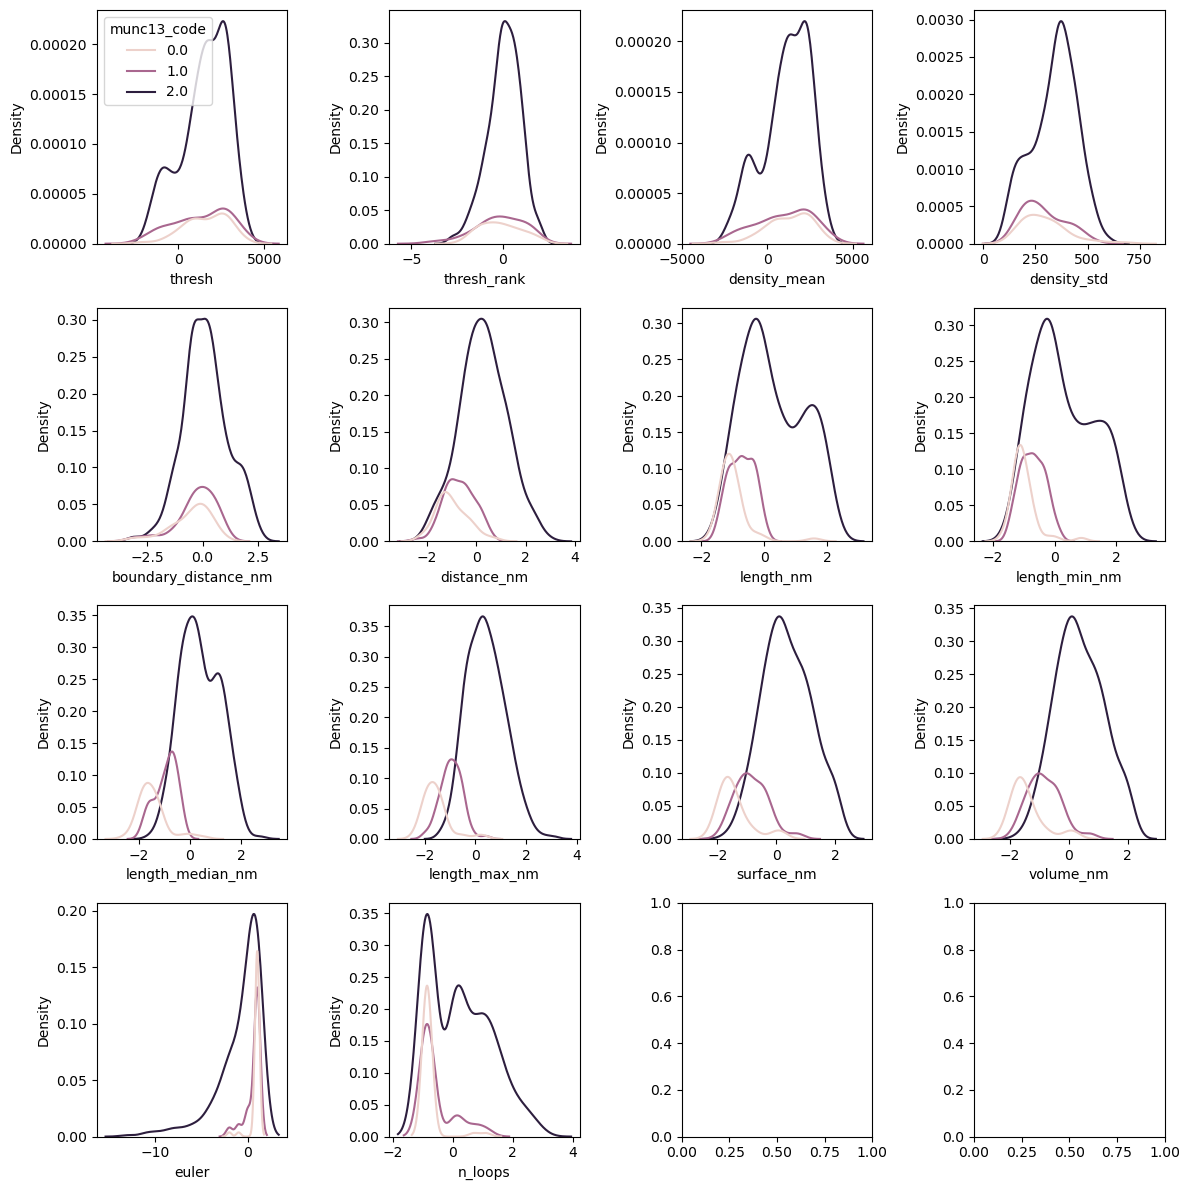

In [27]:
features = features_basic
    
n_cols = 4
data_loc = munc13_data_logstd

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

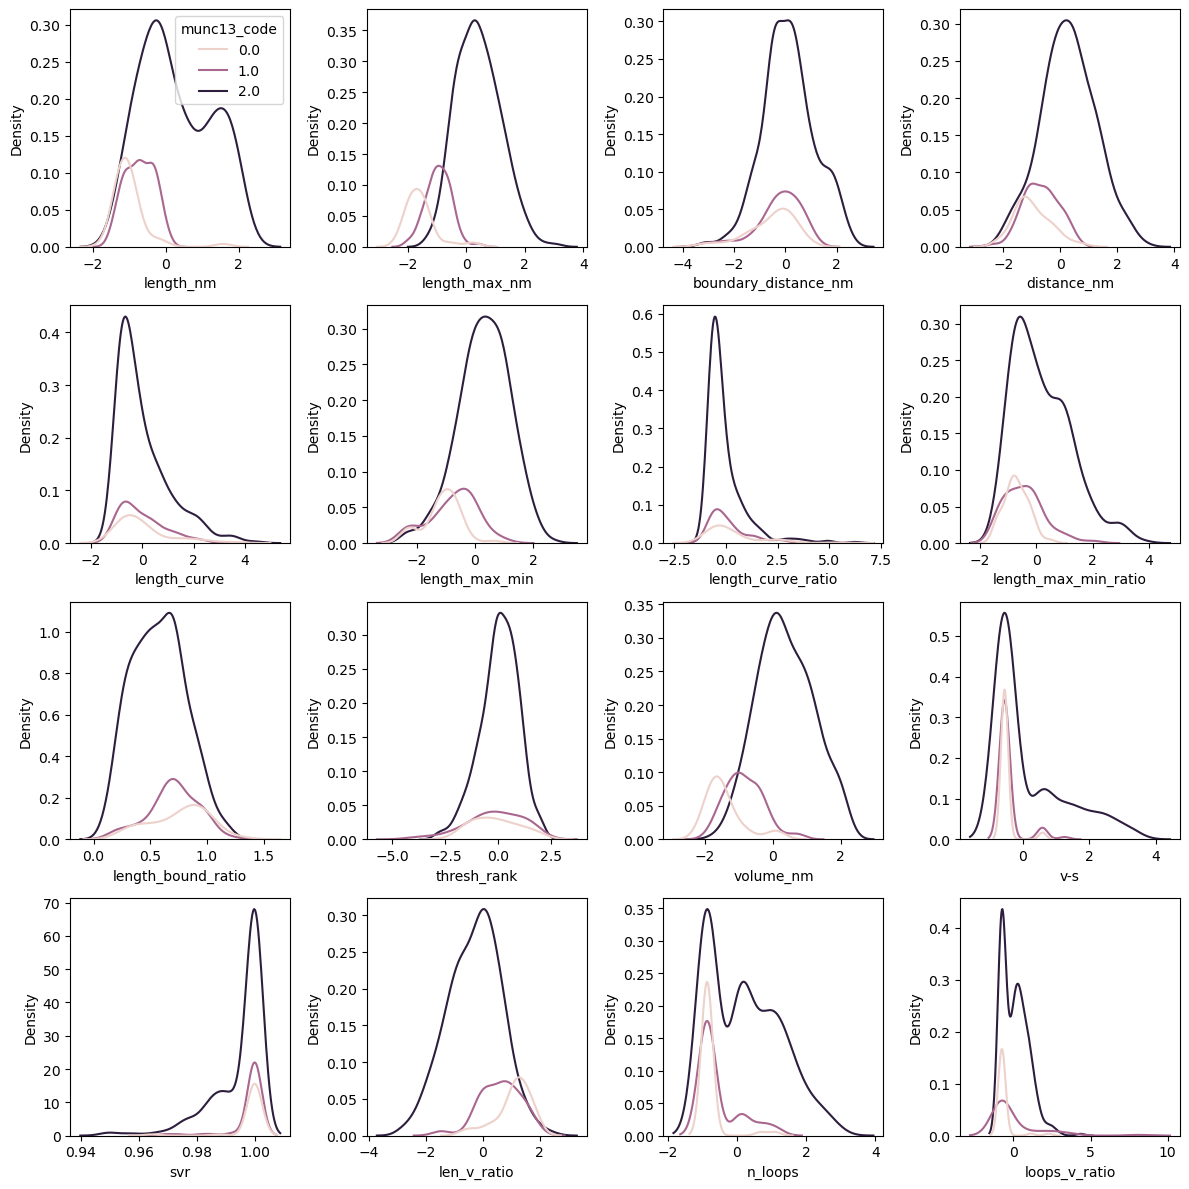

In [28]:
features = features_std
    
n_cols = 4
data_loc = munc13_data_logstd

n_rows = np.ceil(len(features) / n_cols).astype(int)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
legend = True
for ind, feat in enumerate(features):
    curr_row = np.floor(ind / n_cols).astype(int)
    curr_col = ind % n_cols
    sns.kdeplot(
        data=data_loc, x=feat, hue='munc13_code',
        ax=axes[curr_row, curr_col], legend=legend)
    legend = False
fig.tight_layout()

## Pairwise correlations between features

Only some combinations are shown. Many other combinations may be needed for a thorough examination. 

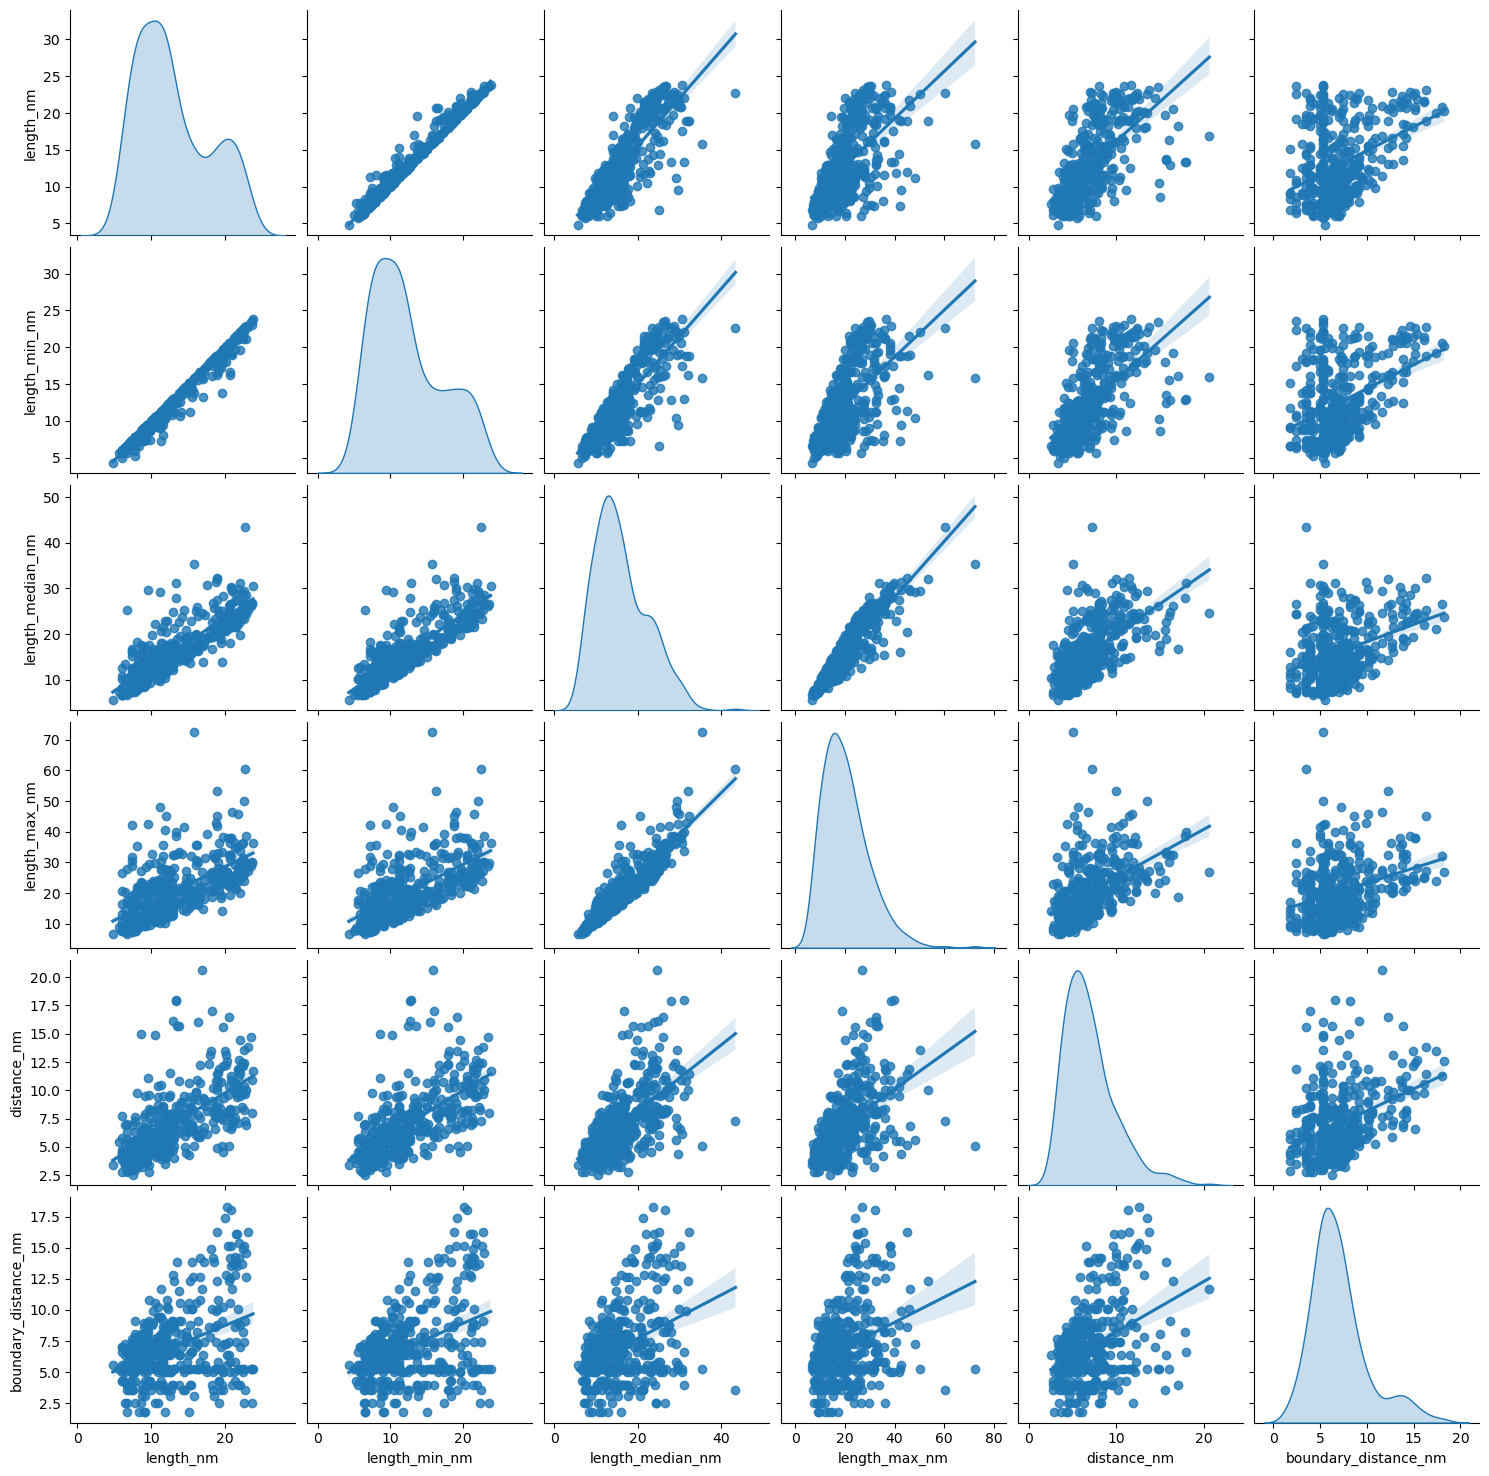

In [29]:
# basic features

cols_loc = [
    'length_nm', 'length_min_nm', 'length_median_nm', 'length_max_nm', 
    'distance_nm', 'boundary_distance_nm']
#short_teth = (snare_data['length_nm'] <= 6)
sns.pairplot(
    munc13_data[cols_loc + ['munc13_code']], vars=cols_loc, kind="reg", 
    diag_kind="kde");

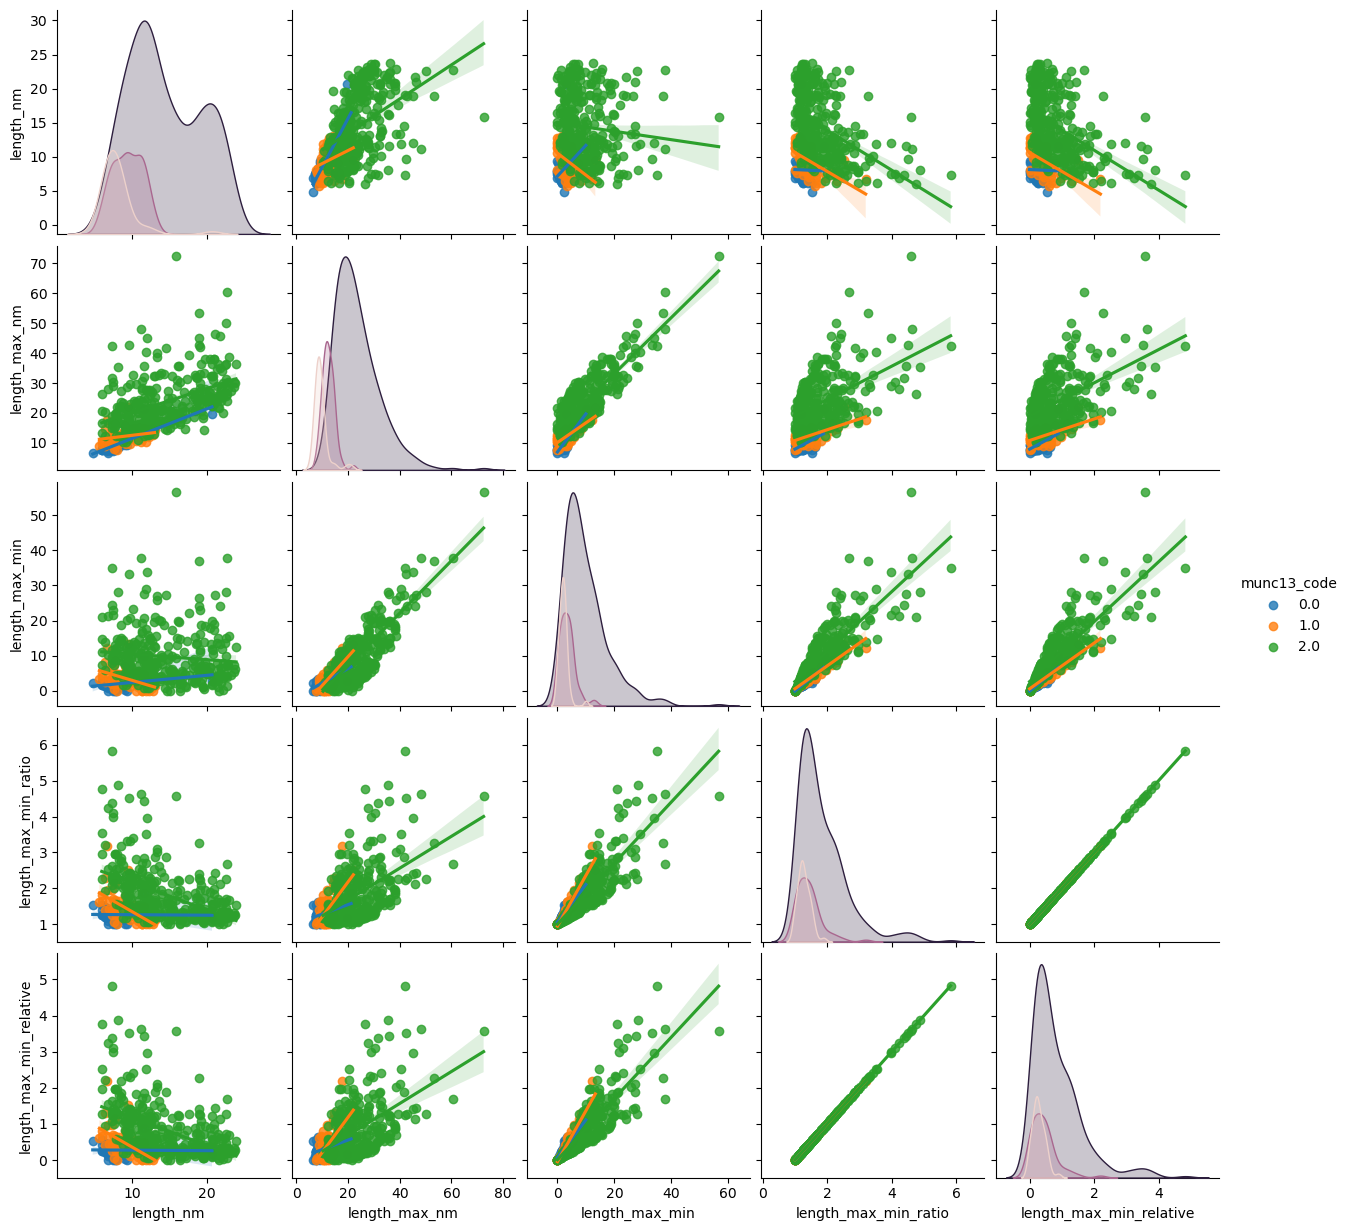

In [30]:
# derived features, color code by munc13 classification

cols_loc = [
    'length_nm', 'length_max_nm', 'length_max_min', 'length_max_min_ratio', 
    'length_max_min_relative']
sns.pairplot(
    munc13_data[cols_loc + ['munc13_code']], vars=cols_loc, kind="reg", 
    diag_kind="kde", hue='munc13_code');

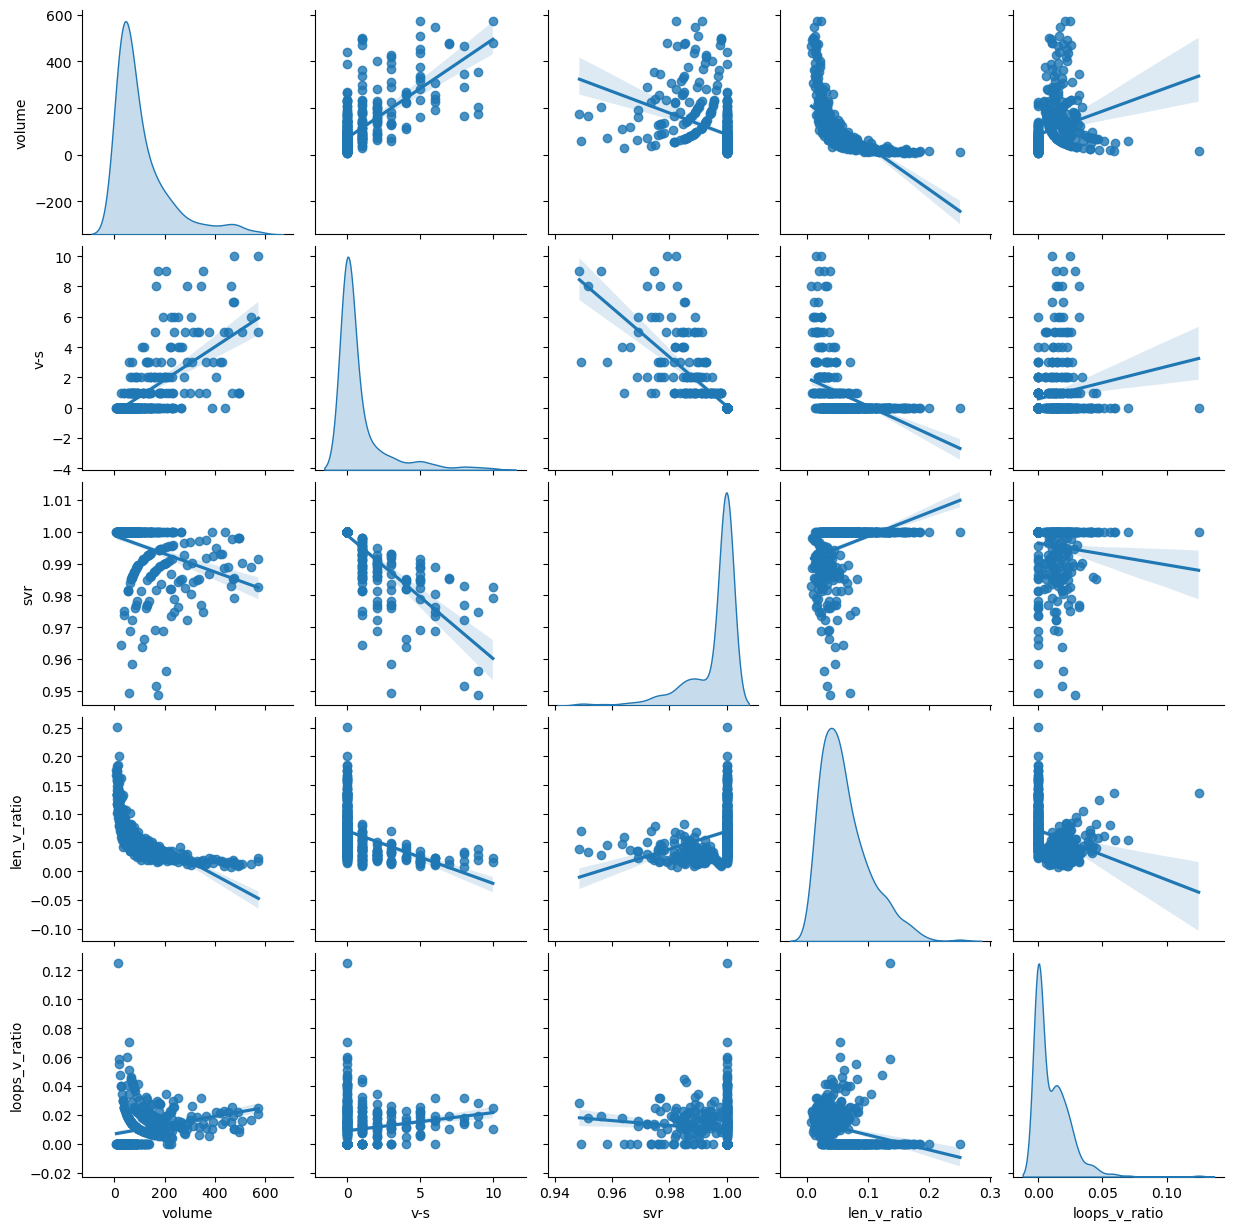

In [31]:
# derived features

cols_loc = [
    'volume', 'v-s', 'svr', 'len_v_ratio', 'loops_v_ratio']
sns.pairplot(
    munc13_data[cols_loc + ['munc13_code']], vars=cols_loc, kind="reg", 
    diag_kind="kde");

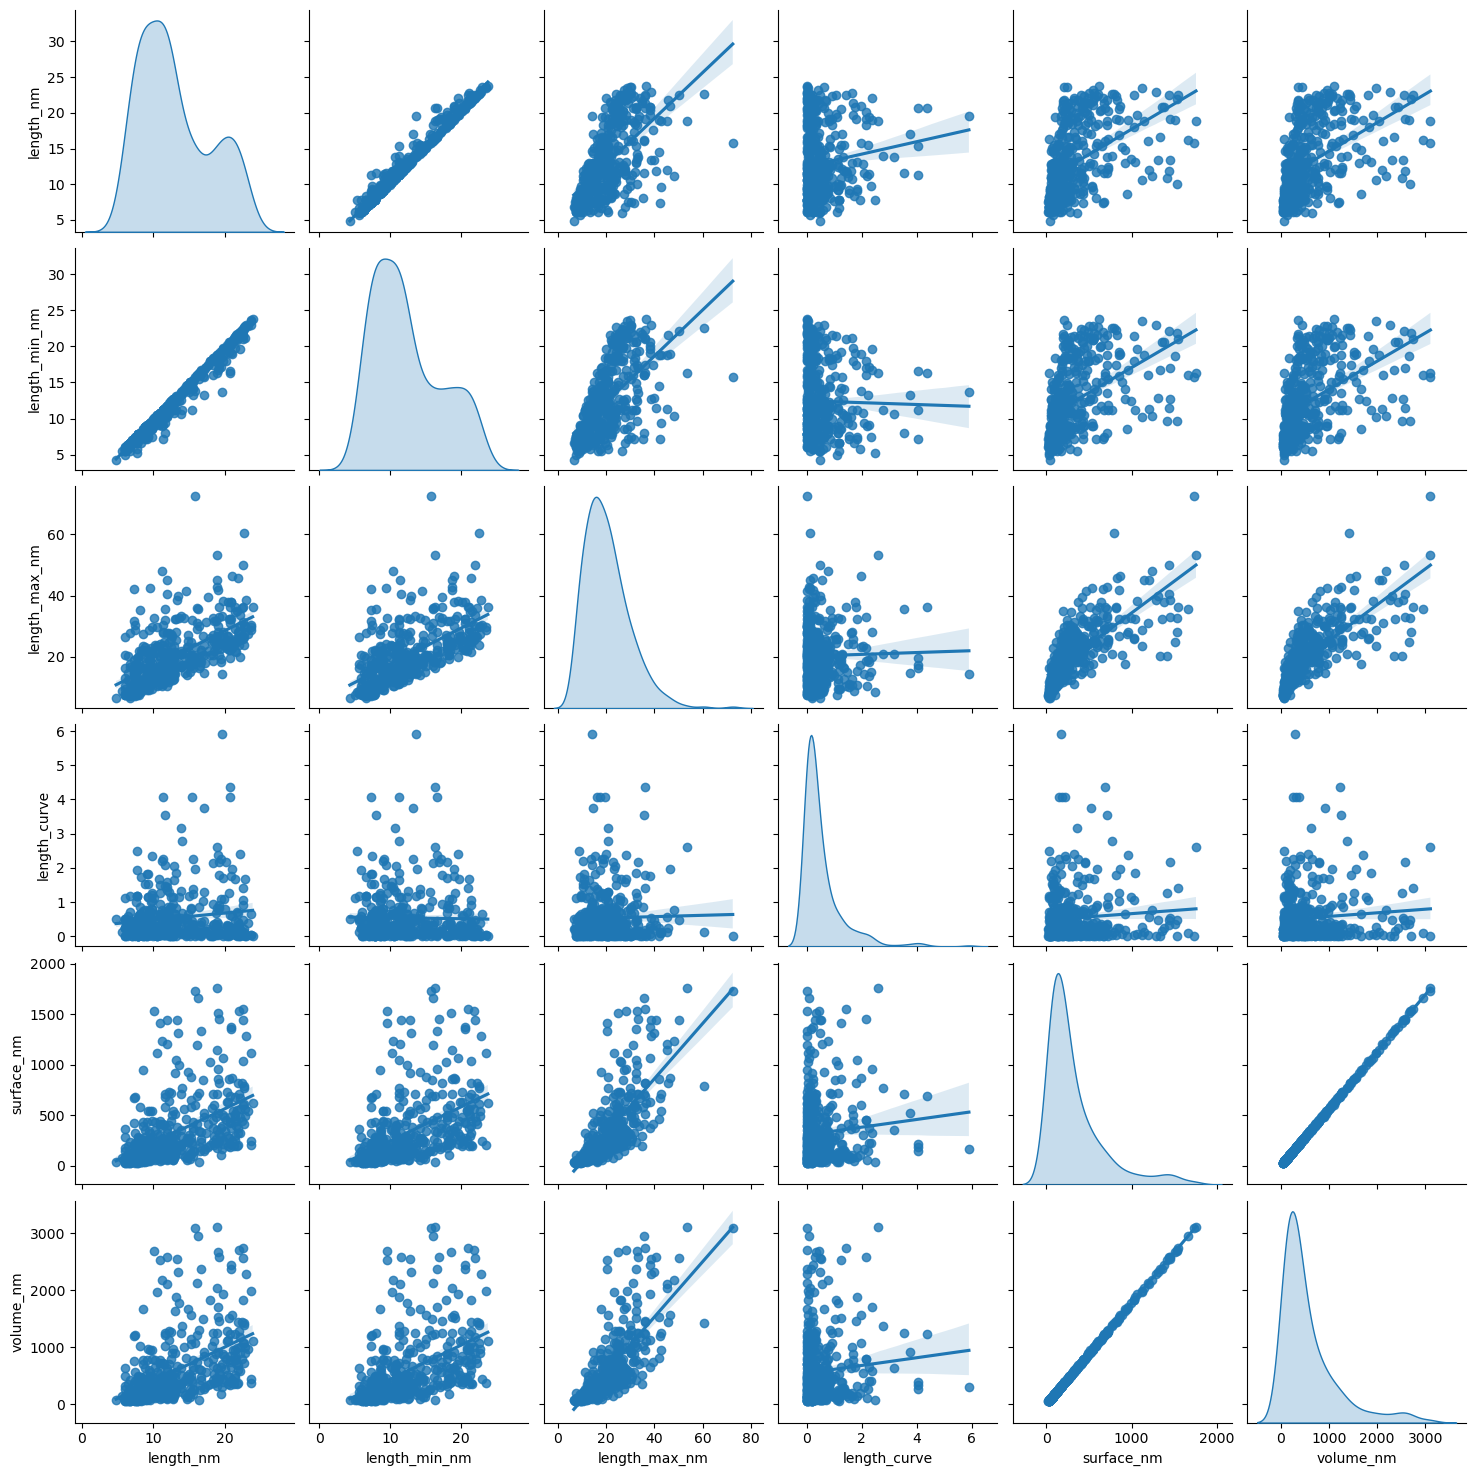

In [32]:
cols_loc = [
    'length_nm', 'length_min_nm', 'length_max_nm', 
    'length_curve',
    'surface_nm', 'volume_nm']
fig = sns.pairplot(
    munc13_data[cols_loc + ['munc13_code']], vars=cols_loc, kind="reg", 
    diag_kind="kde")
#fig.savefig('manuscript_graphs/correlated_features.pdf')

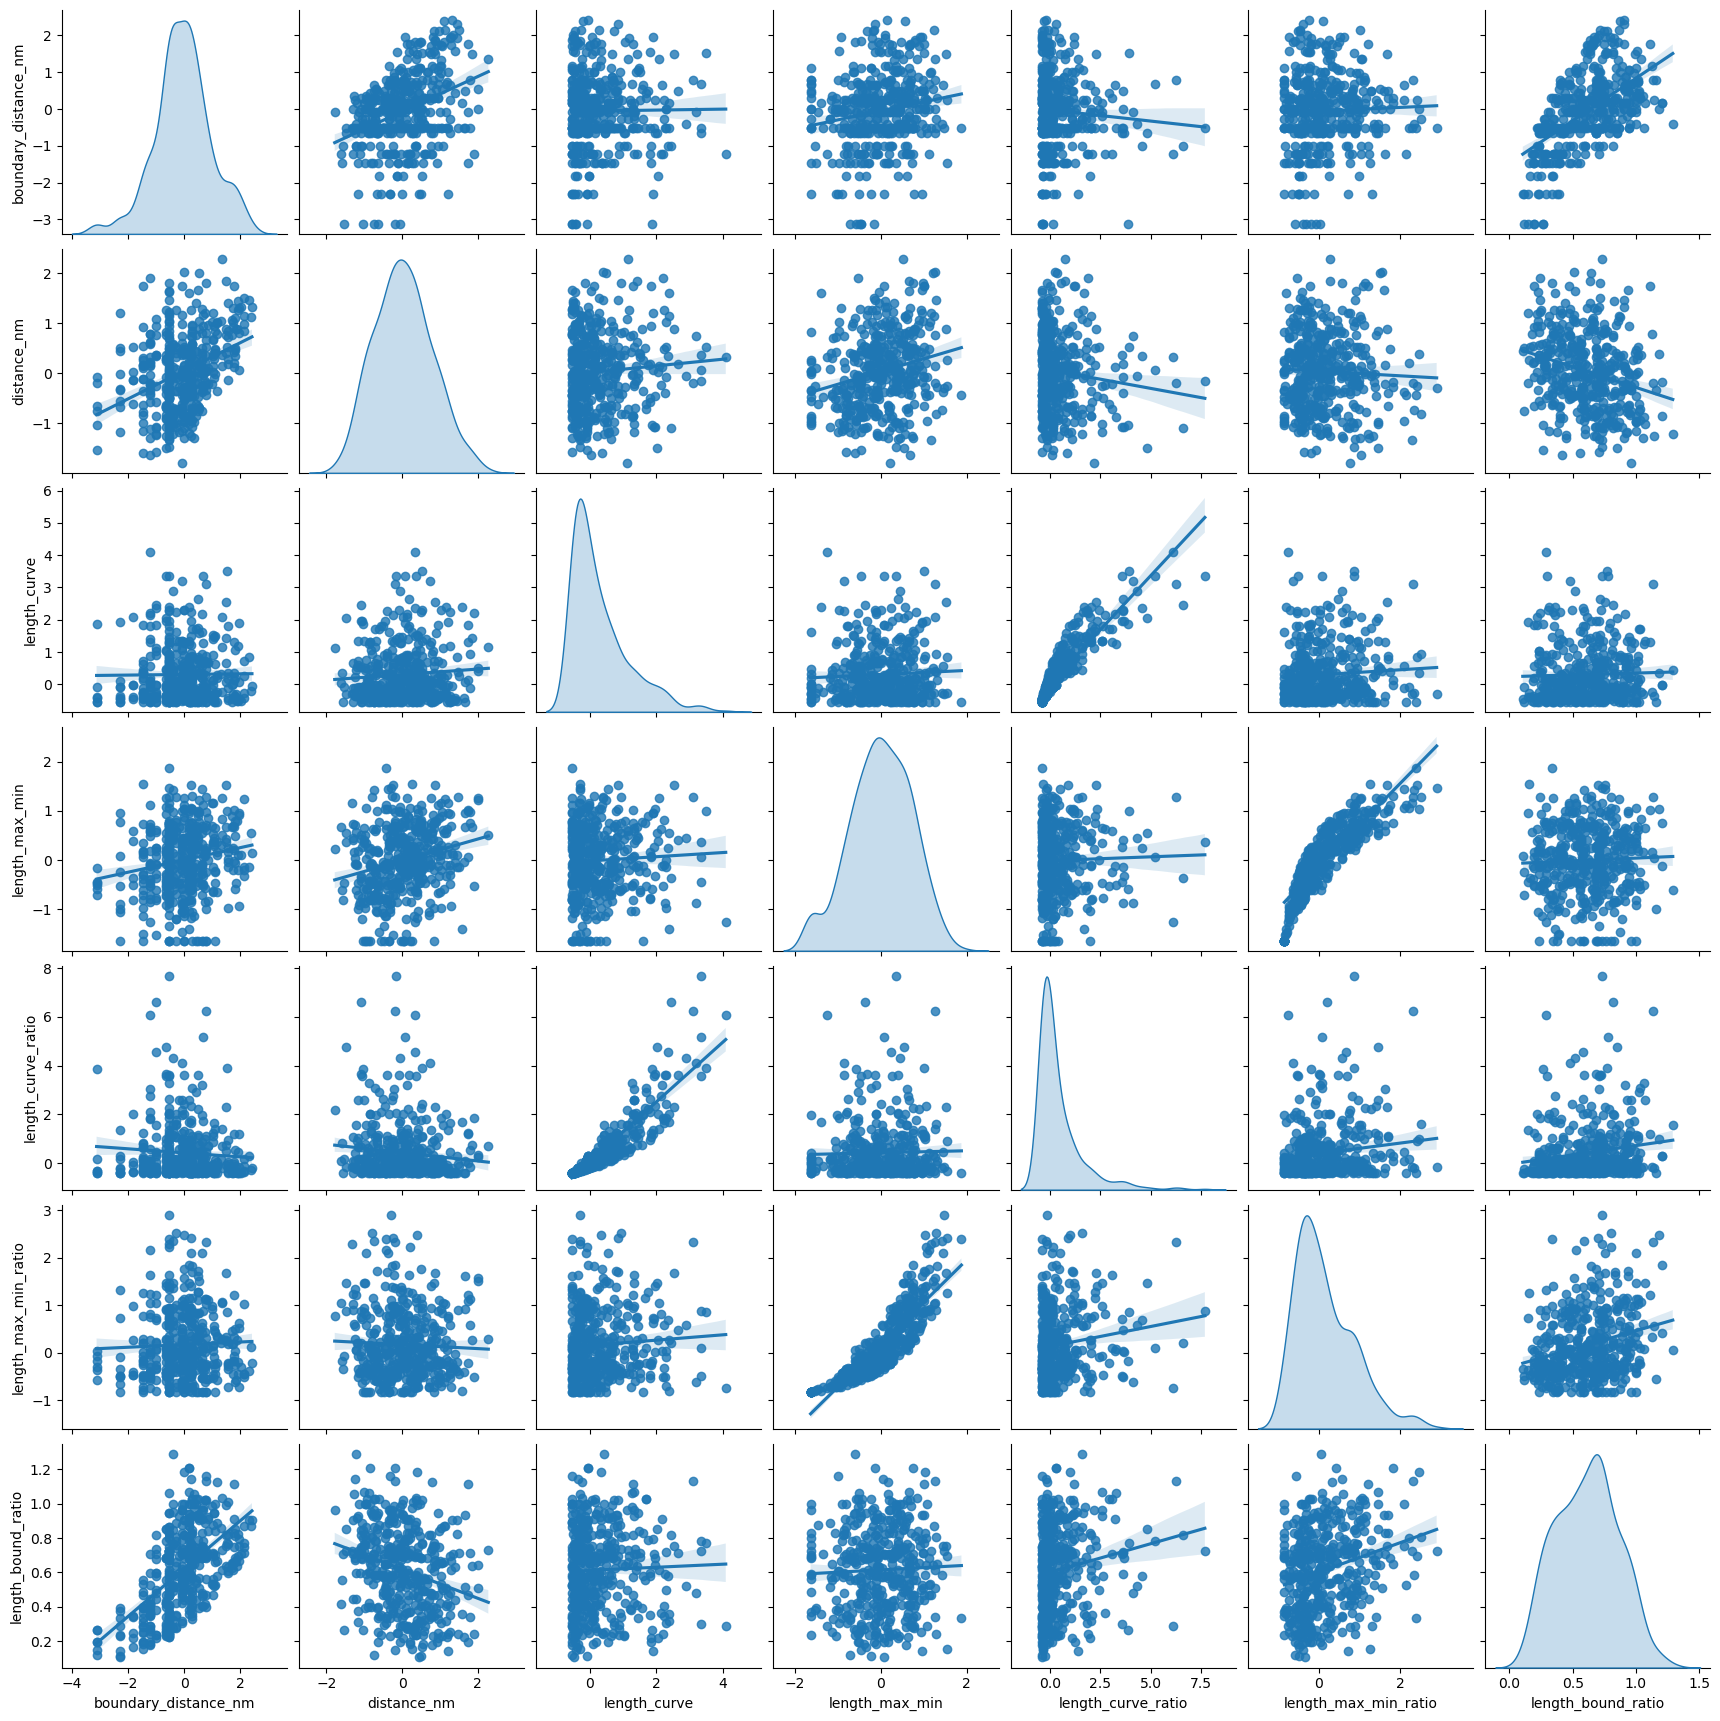

In [33]:
# Selected features, logrobust scaled

munc13_data_logrobust = transform_df(
    data=munc13_data, transformer=get_transformer_logrobust)

cols_loc = ['boundary_distance_nm', 'distance_nm', 'length_curve', 'length_max_min', 
    'length_curve_ratio', 'length_max_min_ratio', 'length_bound_ratio']
sns.pairplot(
    munc13_data_logrobust[cols_loc + ['munc13_code', 'group']], vars=cols_loc, kind="reg", 
    diag_kind="kde");

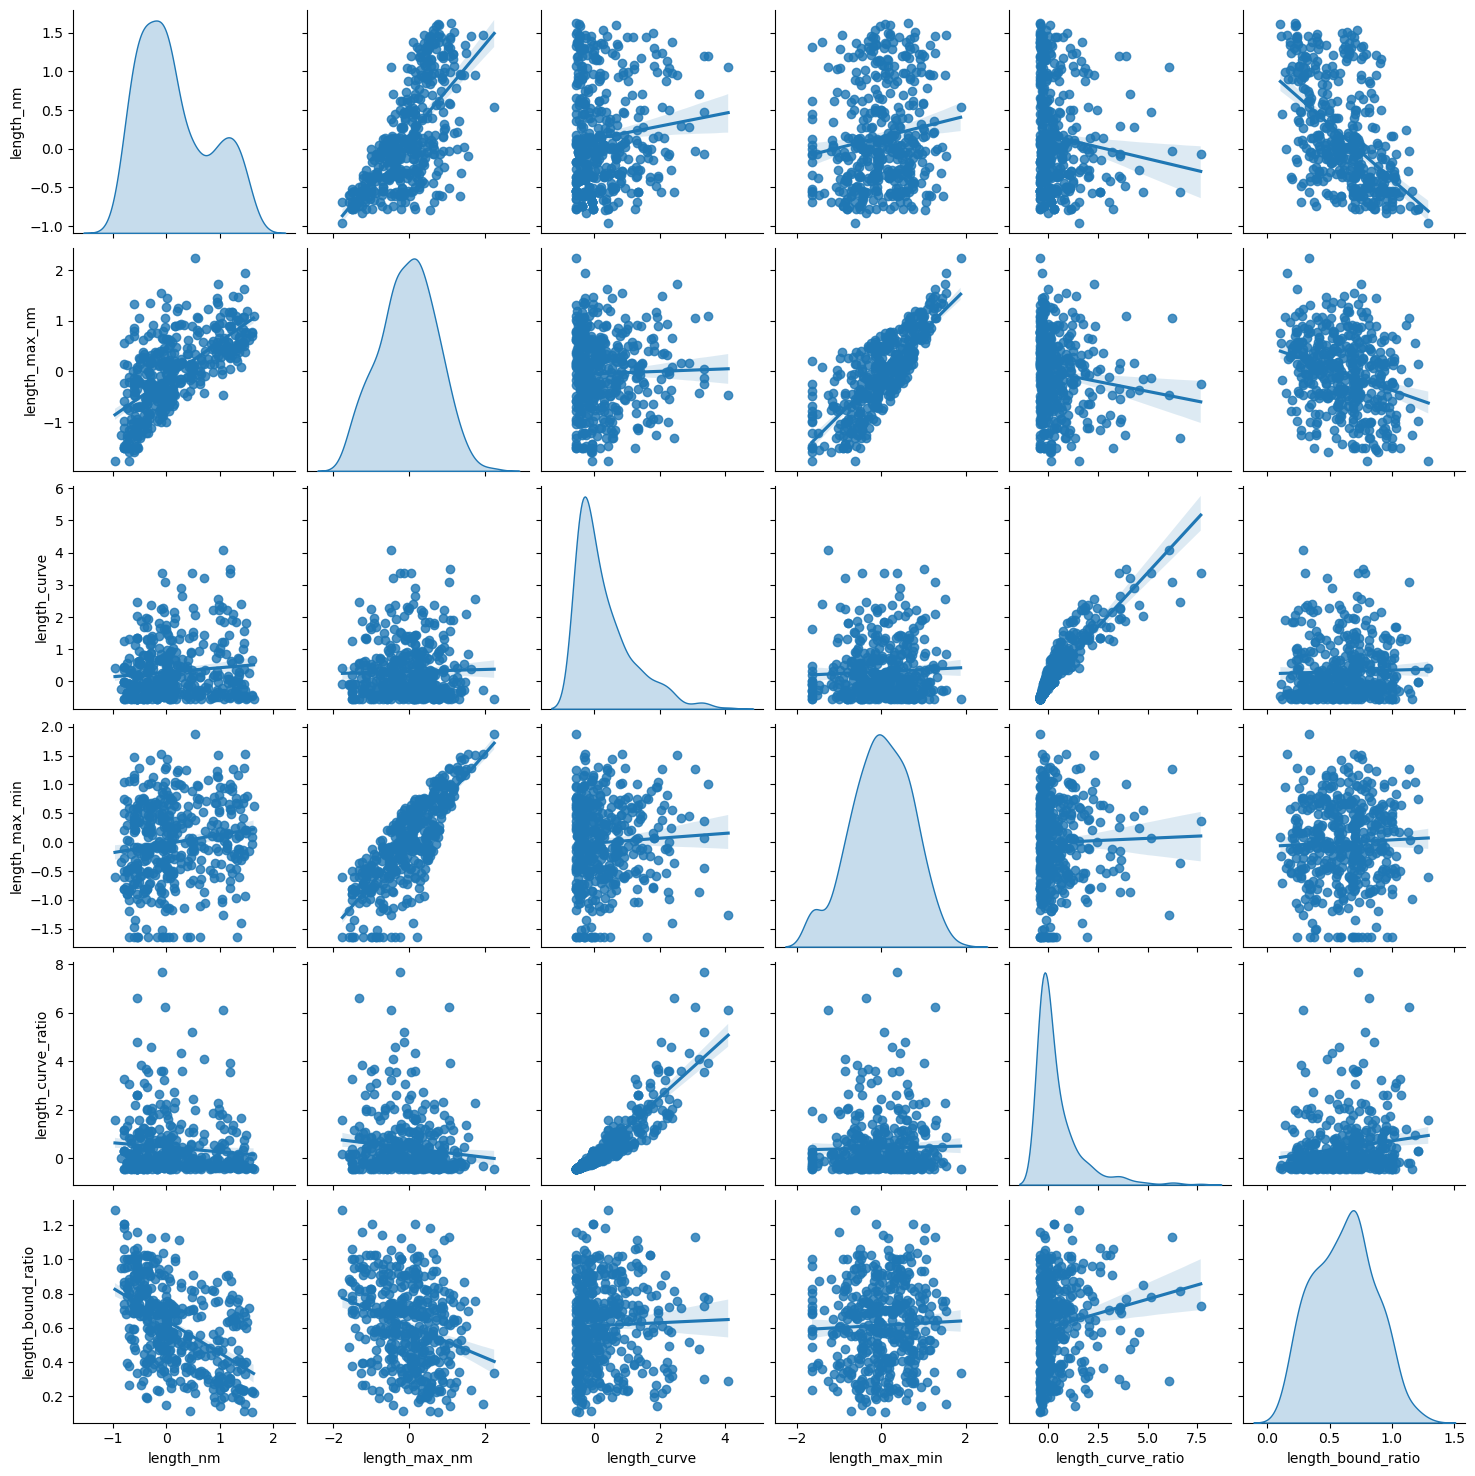

In [34]:
# Logrobust scaled

cols_loc = ['length_nm', 'length_max_nm', 'length_curve', 'length_max_min', 
    'length_curve_ratio', 'length_bound_ratio']
sns.pairplot(
    munc13_data_logrobust[cols_loc + ['munc13_code', 'group']], vars=cols_loc, kind="reg", 
    diag_kind="kde");

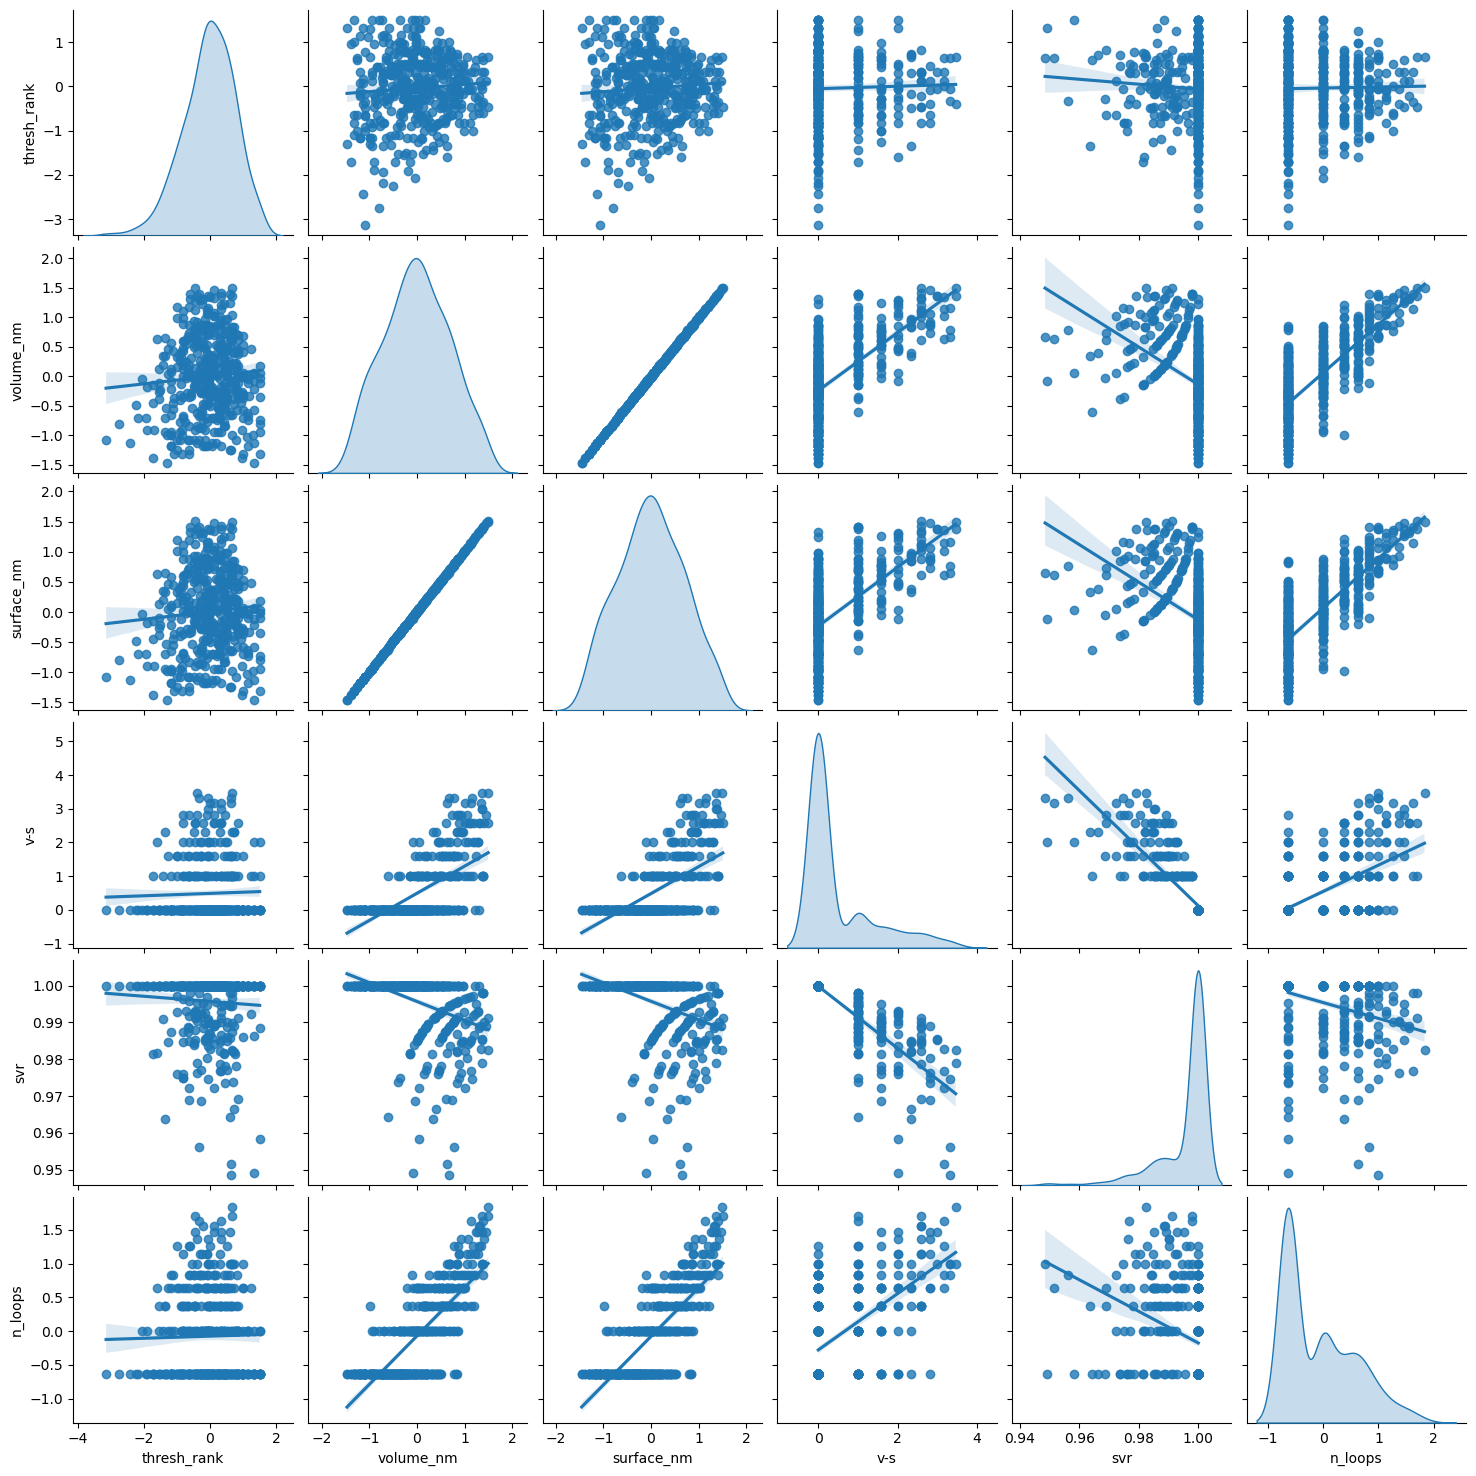

In [35]:
# Logrobust scaled

cols_loc = ['thresh_rank', 'volume_nm', 'surface_nm', 'v-s', 'svr', 'n_loops']
sns.pairplot(
    munc13_data_logrobust[cols_loc + ['munc13_code', 'group']], vars=cols_loc, kind="reg", 
    diag_kind="kde");